<a href="https://colab.research.google.com/github/yimarbriceon/ingenieria-conocimiento-uncp/blob/master/mis-trabajos/laboratorio-3/Cassava_Leaf_Disease_MobileNetV2_TL_Parte2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌿 Parte 2 — Clasificación multi-clase de enfermedades de la yuca (Cassava) con MobileNetV2

**Proyecto universitario — Transfer Learning (Feature Extraction + Fine-Tuning)**

| Campo | Detalle |
|-------|--------|
| **Dataset** | Cassava Leaf Disease (TensorFlow Datasets) |
| **Imágenes** | 9.430 imágenes etiquetadas |
| **Clases** | 5 (CBB, CBSD, CGM, CMD, Healthy) |
| **Arquitectura** | MobileNetV2 (ImageNet) |
| **Estrategia** | Feature Extraction → Fine-Tuning selectivo |
| **Framework** | TensorFlow / Keras |
| **Entorno** | Google Colab + GPU |

---

### Objetivo
Entrenar un modelo capaz de clasificar automáticamente hojas de yuca en una de las 5 categorías (4 enfermedades + sano) utilizando Transfer Learning con MobileNetV2.

## 1. Configuración del entorno

In [1]:
import subprocess
gpu_info = subprocess.run(
    ['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
    capture_output=True, text=True
)
if gpu_info.returncode == 0:
    print("✅ GPU detectada:")
    print(gpu_info.stdout.strip())
else:
    print("⚠️ No se detectó GPU. Se recomienda habilitar Runtime → Change runtime type → GPU.")

✅ GPU detectada:
Tesla T4, 15360 MiB


In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings

warnings.filterwarnings('ignore')

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponible: {tf.config.list_physical_devices('GPU')}")

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Carga del dataset Cassava (TensorFlow Datasets)

El dataset **cassava** está disponible directamente en TFDS:

- **Total**: 9.430 imágenes
- **Train**: 5.656 | **Validation**: 1.889 | **Test**: 1.885
- **Clases**: `cbb`, `cbsd`, `cgm`, `cmd`, `healthy`

| Código | Nombre completo |
|--------|-----------------|
| cbb | Cassava Bacterial Blight |
| cbsd | Cassava Brown Streak Disease |
| cgm | Cassava Green Mite |
| cmd | Cassava Mosaic Disease |
| healthy | Healthy |

In [5]:

!pip install -q importlib-resources

# Cargar dataset con splits oficiales
(train_ds_raw, val_ds_raw, test_ds_raw), info = tfds.load(
    'cassava',
    split=['train', 'validation', 'test'],
    with_info=True,
    as_supervised=True,
    shuffle_files=True
)

CLASS_NAMES = info.features['label'].names
NUM_CLASSES = info.features['label'].num_classes

print("✅ Dataset cargado correctamente")
print(f"Clases ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"Train      : {info.splits['train'].num_examples} imágenes")
print(f"Validation : {info.splits['validation'].num_examples} imágenes")
print(f"Test       : {info.splits['test'].num_examples} imágenes")
print(f"Total      : {info.splits['train'].num_examples + info.splits['validation'].num_examples + info.splits['test'].num_examples} imágenes")

✅ Dataset cargado correctamente
Clases (5): ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Train      : 5656 imágenes
Validation : 1889 imágenes
Test       : 1885 imágenes
Total      : 9430 imágenes


## 3. Exploración y visualización

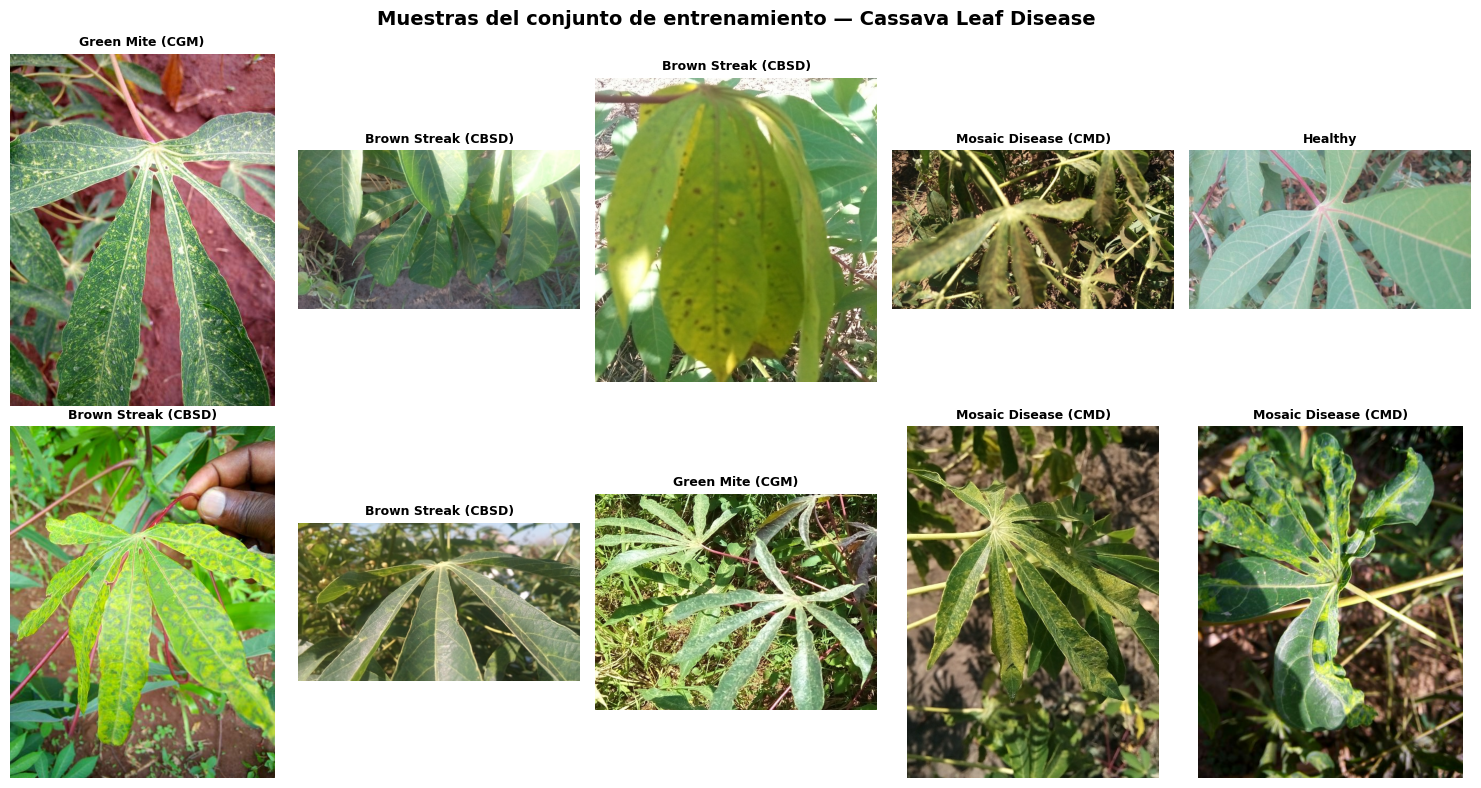

In [6]:
# Nombres legibles de las clases
CLASS_NAMES_FULL = {
    'cbb': 'Bacterial Blight (CBB)',
    'cbsd': 'Brown Streak (CBSD)',
    'cgm': 'Green Mite (CGM)',
    'cmd': 'Mosaic Disease (CMD)',
    'healthy': 'Healthy'
}

# Visualizar muestras
plt.figure(figsize=(15, 8))
for i, (img, label) in enumerate(train_ds_raw.take(10)):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(img.numpy().astype('uint8'))
    label_name = CLASS_NAMES[int(label.numpy())]
    plt.title(CLASS_NAMES_FULL.get(label_name, label_name), fontsize=9, fontweight='bold')
    plt.axis('off')
plt.suptitle('Muestras del conjunto de entrenamiento — Cassava Leaf Disease',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

📊 Distribución de clases:
Train: {'cbb': np.int64(466), 'cbsd': np.int64(1443), 'cgm': np.int64(773), 'cmd': np.int64(2658), 'healthy': np.int64(316)}
Val: {'cbb': np.int64(156), 'cbsd': np.int64(482), 'cgm': np.int64(258), 'cmd': np.int64(887), 'healthy': np.int64(106)}
Test: {'cbb': np.int64(155), 'cbsd': np.int64(481), 'cgm': np.int64(258), 'cmd': np.int64(886), 'healthy': np.int64(105)}


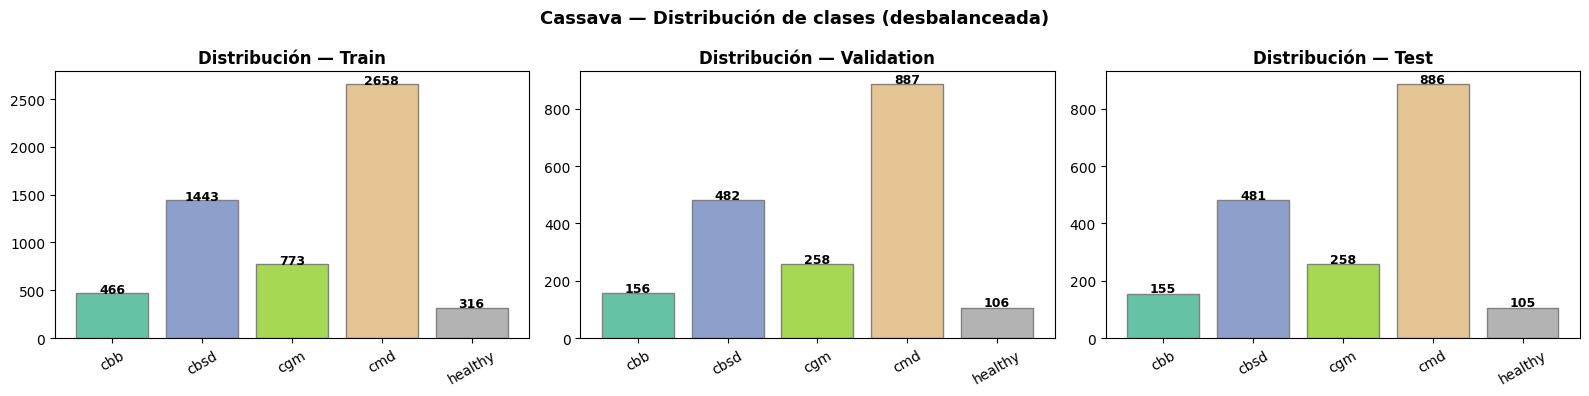

In [7]:
# Distribución de clases
def count_labels(dataset, name):
    labels = [int(label.numpy()) for _, label in dataset]
    unique, counts = np.unique(labels, return_counts=True)
    dist = {CLASS_NAMES[u]: c for u, c in zip(unique, counts)}
    print(f"{name}: {dist}")
    return dist

print("📊 Distribución de clases:")
train_dist = count_labels(train_ds_raw, "Train")
val_dist   = count_labels(val_ds_raw, "Val")
test_dist  = count_labels(test_ds_raw, "Test")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, dist, title in zip(axes, [train_dist, val_dist, test_dist],
                           ['Train', 'Validation', 'Test']):
    bars = ax.bar(dist.keys(), dist.values(), color=plt.cm.Set2(np.linspace(0, 1, 5)), edgecolor='gray')
    ax.set_title(f'Distribución — {title}', fontweight='bold')
    ax.tick_params(axis='x', rotation=30)
    for bar, count in zip(bars, dist.values()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(count), ha='center', fontsize=9, fontweight='bold')
plt.suptitle('Cassava — Distribución de clases (desbalanceada)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 4. Preprocesamiento y Data Augmentation

- Tamaño de entrada de MobileNetV2: **224 × 224**
- Usamos **exclusivamente** `mobilenet_v2.preprocess_input`
- Data Augmentation **solo** en el conjunto de entrenamiento

In [8]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name='data_augmentation')

def preprocess_train(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = data_augmentation(image, training=True)
    image = preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

def preprocess_val_test(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

train_ds = (train_ds_raw
            .map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
            .shuffle(1000, seed=SEED)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

val_ds = (val_ds_raw
          .map(preprocess_val_test, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

test_ds = (test_ds_raw
           .map(preprocess_val_test, num_parallel_calls=tf.data.AUTOTUNE)
           .batch(BATCH_SIZE)
           .prefetch(tf.data.AUTOTUNE))

print("✅ Pipelines de datos listos (augmentation solo en train).")

✅ Pipelines de datos listos (augmentation solo en train).


## 5. Construcción del modelo — Feature Extraction (MobileNetV2)

In [9]:
base_model = MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False   # Feature Extraction: backbone congelado

inputs = layers.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model_fe = models.Model(inputs, outputs, name='Cassava_MobileNetV2_FE')

total_params = model_fe.count_params()
trainable_params = sum(tf.size(w).numpy() for w in model_fe.trainable_weights)
print("📐 MobileNetV2 — Feature Extraction")
print(f"   Total de parámetros : {total_params:,}")
print(f"   Entrenables         : {trainable_params:,}")
print(f"   Congelados          : {total_params - trainable_params:,}")
model_fe.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
📐 MobileNetV2 — Feature Extraction
   Total de parámetros : 2,427,717
   Entrenables         : 167,173
   Congelados          : 2,260,544


Model: "Cassava_MobileNetV2_FE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,427,717 (9.26 MB)

 Trainable params: 167,173 (653.02 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 6. Compilación y entrenamiento — Feature Extraction

In [10]:
model_fe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("🚀 Entrenando Feature Extraction...")
history_fe = model_fe.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop, reduce_lr]
)

print(f"\n🏆 Mejor val_accuracy (FE): {max(history_fe.history['val_accuracy']):.4f}")

🚀 Entrenando Feature Extraction...
Epoch 1/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 110s 464ms/step - accuracy: 0.5870 - loss: 1.2369 - val_accuracy: 0.6977 - val_loss: 0.8155 - learning_rate: 0.0010
Epoch 2/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 79s 376ms/step - accuracy: 0.6777 - loss: 0.9062 - val_accuracy: 0.7125 - val_loss: 0.7888 - learning_rate: 0.0010
Epoch 3/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 83s 398ms/step - accuracy: 0.6915 - loss: 0.8230 - val_accuracy: 0.7200 - val_loss: 0.7731 - learning_rate: 0.0010
Epoch 4/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 79s 374ms/step - accuracy: 0.7217 - loss: 0.7529 - val_accuracy: 0.7168 - val_loss: 0.7695 - learning_rate: 0.0010
Epoch 5/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 83s 396ms/step - accuracy: 0.7176 - loss: 0.7470 - val_accuracy: 0.7210 - val_loss: 0.7776 - learning_rate: 0.0010
Epoch 6/20
177/177 ━━━━━━━━━━━━━━━━━━━━ 78s 374ms/step - accuracy: 0.7323 - loss: 0.7297 - val_accuracy: 0.7210 - val_loss: 0.7651 - learning_rate: 0.0010
Epoch 7/20
177/177 ━━━━━━━━━━━━━━━

## 7. Curvas de aprendizaje — Feature Extraction

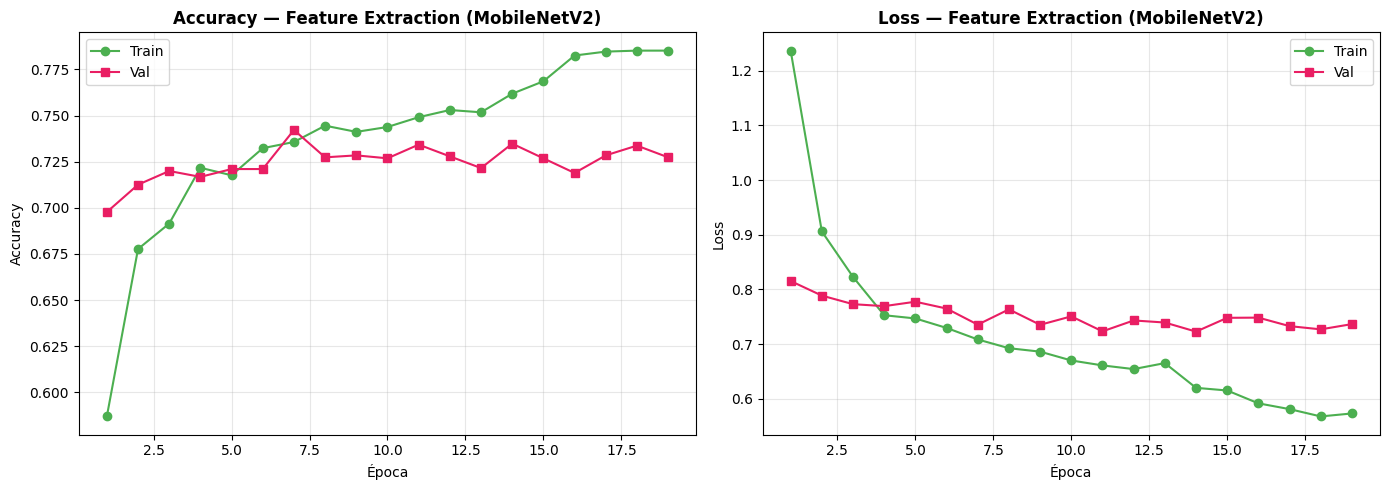

In [11]:
def plot_history(history, title_suffix=''):
    ep = range(1, len(history.history['accuracy']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(ep, history.history['accuracy'], 'o-', label='Train', color='#4CAF50')
    axes[0].plot(ep, history.history['val_accuracy'], 's-', label='Val', color='#E91E63')
    axes[0].set_title(f'Accuracy {title_suffix}', fontweight='bold')
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(ep, history.history['loss'], 'o-', label='Train', color='#4CAF50')
    axes[1].plot(ep, history.history['val_loss'], 's-', label='Val', color='#E91E63')
    axes[1].set_title(f'Loss {title_suffix}', fontweight='bold')
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_fe, '— Feature Extraction (MobileNetV2)')

## 8. Evaluación detallada — Feature Extraction


📊 Resultados en conjunto Test (Feature Extraction)
Accuracy: 0.7363

Classification Report:
              precision    recall  f1-score   support

         cbb     0.4839    0.5806    0.5279       155
        cbsd     0.7035    0.6757    0.6893       481
         cgm     0.7183    0.5930    0.6497       258
         cmd     0.8800    0.8273    0.8528       886
     healthy     0.4555    0.8286    0.5878       105

    accuracy                         0.7363      1885
   macro avg     0.6482    0.7010    0.6615      1885
weighted avg     0.7566    0.7363    0.7418      1885



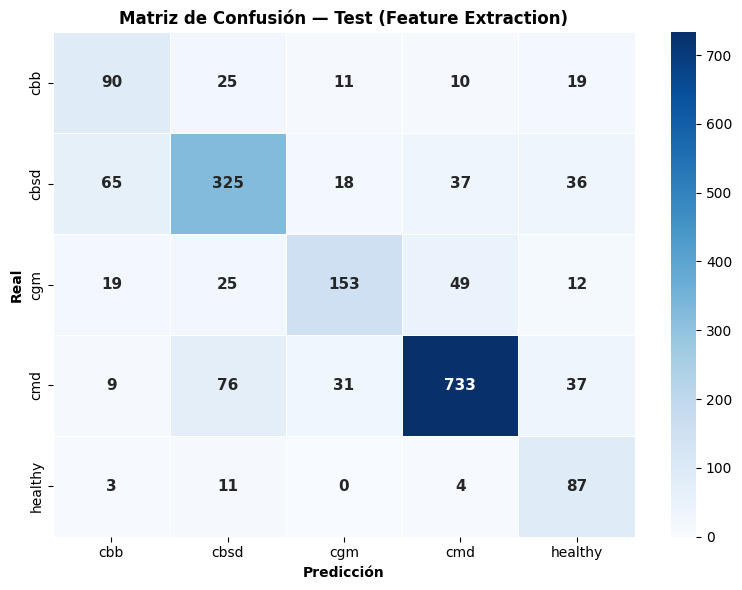

In [12]:
def evaluate_model(model, dataset, set_name='Test'):
    y_true, y_pred = [], []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(np.argmax(labels.numpy(), axis=1))

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    acc = accuracy_score(y_true, y_pred)
    print(f"\n📊 Resultados en conjunto {set_name}")
    print("=" * 60)
    print(f"Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax,
                linewidths=0.5, annot_kws={'size': 11, 'fontweight': 'bold'})
    ax.set_xlabel('Predicción', fontweight='bold')
    ax.set_ylabel('Real', fontweight='bold')
    ax.set_title(f'Matriz de Confusión — {set_name}', fontweight='bold')
    plt.tight_layout()
    plt.show()

    return {'accuracy': acc, 'cm': cm, 'y_true': y_true, 'y_pred': y_pred}

results_fe = evaluate_model(model_fe, test_ds, set_name='Test (Feature Extraction)')

## 9. Fine-Tuning selectivo

Descongelamos las últimas capas del backbone y re-entrenamos con un learning rate mucho más bajo.

In [13]:
# Descongelar backbone
base_model.trainable = True

# Congelar las capas tempranas (dejar solo las últimas entrenables)
fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"Capas del backbone : {len(base_model.layers)}")
print(f"Capas congeladas   : {fine_tune_at}")
print(f"Capas entrenables  : {len(base_model.layers) - fine_tune_at}")

trainable_params_ft = sum(tf.size(w).numpy() for w in model_fe.trainable_weights)
print(f"Parámetros entrenables ahora: {trainable_params_ft:,}")

Capas del backbone : 154
Capas congeladas   : 100
Capas entrenables  : 54
Parámetros entrenables ahora: 2,028,613


In [14]:
model_fe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),   # LR bajo
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_ft = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_ft = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

print("🚀 Iniciando Fine-Tuning...")
history_ft = model_fe.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop_ft, reduce_lr_ft]
)

print(f"\n🏆 Mejor val_accuracy (Fine-Tuning): {max(history_ft.history['val_accuracy']):.4f}")

🚀 Iniciando Fine-Tuning...
Epoch 1/15
177/177 ━━━━━━━━━━━━━━━━━━━━ 127s 506ms/step - accuracy: 0.6406 - loss: 0.9350 - val_accuracy: 0.7268 - val_loss: 0.8921 - learning_rate: 1.0000e-05
Epoch 2/15
177/177 ━━━━━━━━━━━━━━━━━━━━ 82s 396ms/step - accuracy: 0.6878 - loss: 0.8252 - val_accuracy: 0.7390 - val_loss: 0.9574 - learning_rate: 1.0000e-05
Epoch 3/15
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 359ms/step - accuracy: 0.7094 - loss: 0.7614
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
177/177 ━━━━━━━━━━━━━━━━━━━━ 141s 389ms/step - accuracy: 0.7122 - loss: 0.7606 - val_accuracy: 0.7491 - val_loss: 0.8996 - learning_rate: 1.0000e-05
Epoch 4/15
177/177 ━━━━━━━━━━━━━━━━━━━━ 81s 389ms/step - accuracy: 0.7228 - loss: 0.7412 - val_accuracy: 0.7554 - val_loss: 0.8419 - learning_rate: 5.0000e-06
Epoch 5/15
177/177 ━━━━━━━━━━━━━━━━━━━━ 83s 393ms/step - accuracy: 0.7313 - loss: 0.7392 - val_accuracy: 0.7639 - val_loss: 0.7835 - learning_rate: 5.0000e-06
Epoch 6/15
177/177 ━━━━

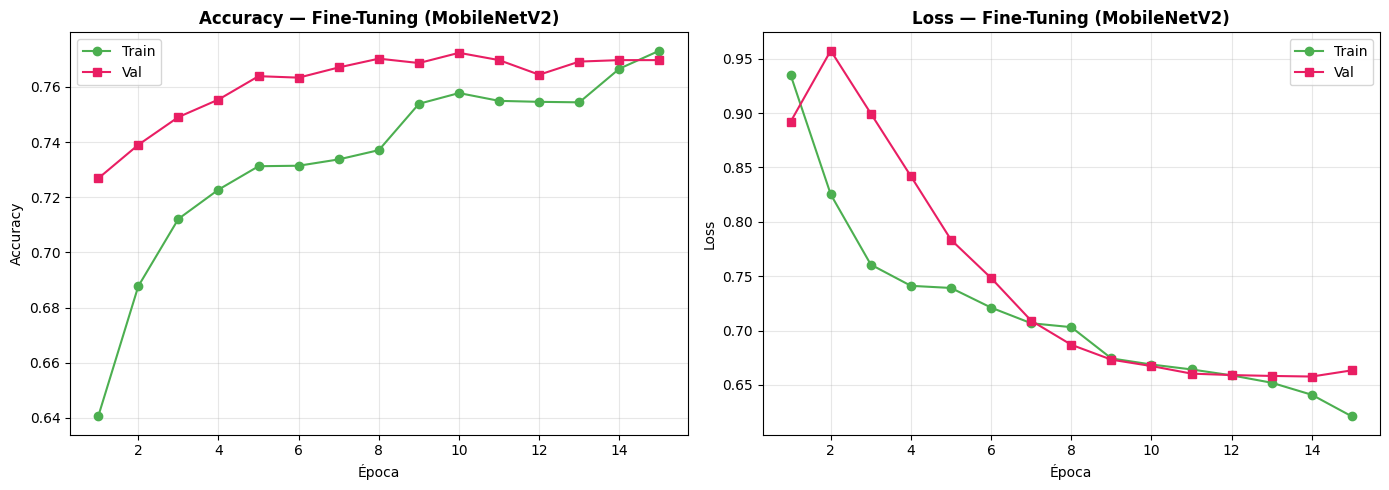

In [15]:
plot_history(history_ft, '— Fine-Tuning (MobileNetV2)')

## 10. Evaluación final después de Fine-Tuning


📊 Resultados en conjunto Test (Fine-Tuning)
Accuracy: 0.7809

Classification Report:
              precision    recall  f1-score   support

         cbb     0.6082    0.3806    0.4683       155
        cbsd     0.7176    0.8295    0.7695       481
         cgm     0.7366    0.6395    0.6846       258
         cmd     0.8867    0.8657    0.8761       886
     healthy     0.5734    0.7810    0.6613       105

    accuracy                         0.7809      1885
   macro avg     0.7045    0.6993    0.6920      1885
weighted avg     0.7827    0.7809    0.7772      1885



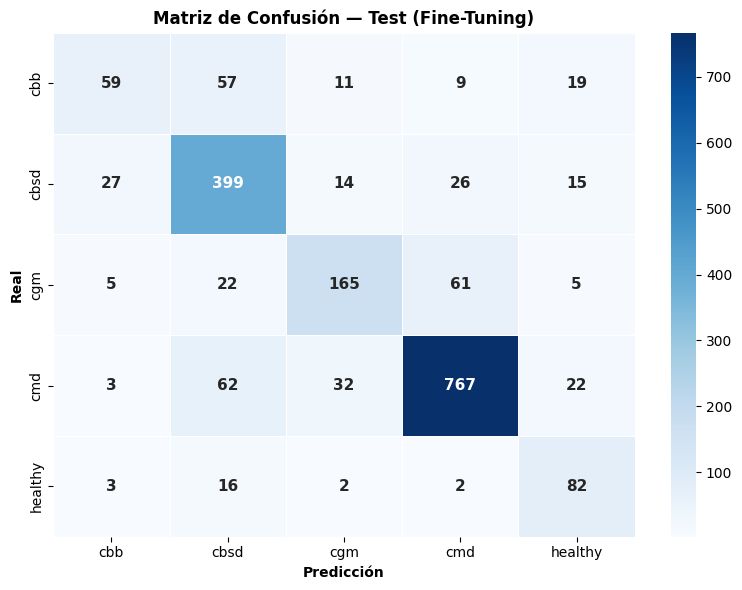

In [16]:
results_ft = evaluate_model(model_fe, test_ds, set_name='Test (Fine-Tuning)')

## 11. Comparación Feature Extraction vs Fine-Tuning


📊 TABLA COMPARATIVA
        Métrica  Feature Extraction  Fine-Tuning
Accuracy (Test)             0.73634     0.780902


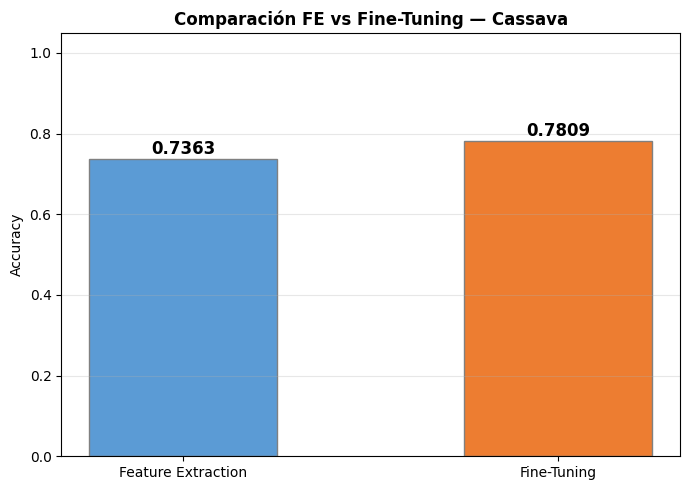

In [17]:
comparison = pd.DataFrame({
    'Métrica': ['Accuracy (Test)'],
    'Feature Extraction': [results_fe['accuracy']],
    'Fine-Tuning': [results_ft['accuracy']]
})

print("\n📊 TABLA COMPARATIVA")
print("=" * 45)
print(comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(['Feature Extraction', 'Fine-Tuning'],
              [results_fe['accuracy'], results_ft['accuracy']],
              color=['#5B9BD5', '#ED7D31'], edgecolor='gray', width=0.5)
ax.set_ylabel('Accuracy')
ax.set_title('Comparación FE vs Fine-Tuning — Cassava', fontweight='bold')
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3, axis='y')

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 4), textcoords='offset points',
                ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

## 12. Predicciones de ejemplo en el conjunto de test

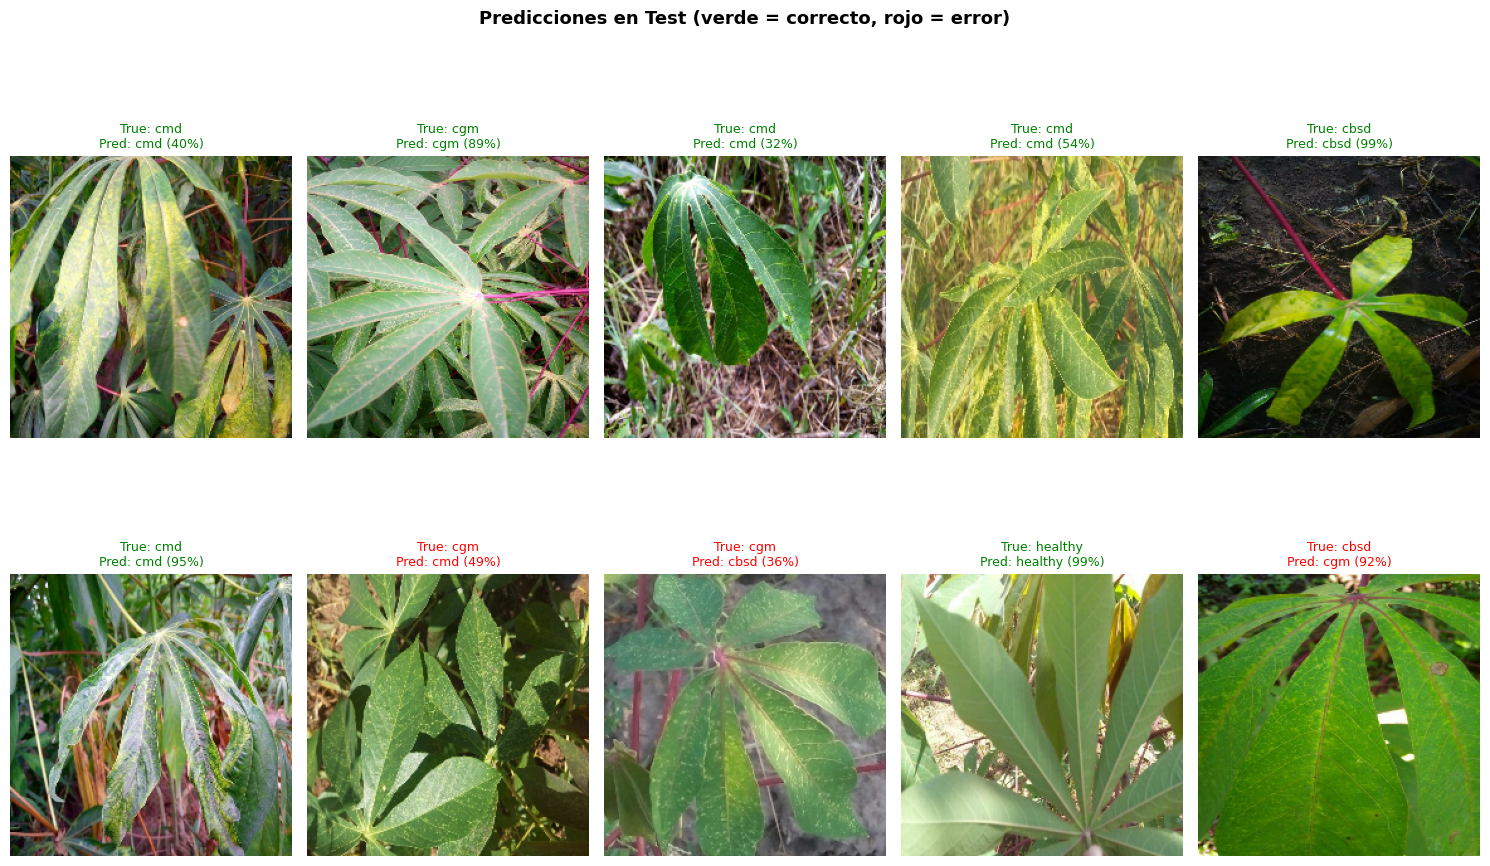

In [18]:
plt.figure(figsize=(15, 10))
count = 0
for images, labels in test_ds.take(2):
    preds = model_fe.predict(images, verbose=0)
    for i in range(min(10, images.shape[0])):
        if count >= 10:
            break
        ax = plt.subplot(2, 5, count + 1)
        # Recuperar imagen aproximada (rango [-1,1] → [0,1])
        img_display = (images[i].numpy() + 1.0) / 2.0
        img_display = np.clip(img_display, 0, 1)
        plt.imshow(img_display)

        true_idx = np.argmax(labels[i].numpy())
        pred_idx = np.argmax(preds[i])
        conf = preds[i][pred_idx]

        true_name = CLASS_NAMES[true_idx]
        pred_name = CLASS_NAMES[pred_idx]
        color = 'green' if true_idx == pred_idx else 'red'

        plt.title(f'True: {true_name}\nPred: {pred_name} ({conf:.0%})',
                  color=color, fontsize=9)
        plt.axis('off')
        count += 1
plt.suptitle('Predicciones en Test (verde = correcto, rojo = error)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 13. Guardado del modelo

In [19]:
MODEL_PATH = '/content/cassava_mobilenetv2_ft.keras'
model_fe.save(MODEL_PATH)
print(f"✅ Modelo guardado en: {MODEL_PATH}")

# Verificar carga
loaded = tf.keras.models.load_model(MODEL_PATH)
print("✅ Modelo recargado correctamente.")
print(f"   Capas: {len(loaded.layers)}")

✅ Modelo guardado en: /content/cassava_mobilenetv2_ft.keras
✅ Modelo recargado correctamente.
   Capas: 8


## 14. Resumen final — Parte 2

| Aspecto | Detalle |
|---------|--------|
| **Dataset** | Cassava Leaf Disease (TFDS) — 9.430 imágenes |
| **Clases** | 5 (CBB, CBSD, CGM, CMD, Healthy) |
| **Backbone** | MobileNetV2 (ImageNet) |
| **Estrategia 1** | Feature Extraction (backbone congelado) |
| **Estrategia 2** | Fine-Tuning (últimas capas + LR bajo) |
| **Preprocesamiento** | `mobilenet_v2.preprocess_input` |
| **Augmentation** | Flip, Rotation, Zoom, Contrast |
| **Regularización** | Dropout + EarlyStopping + ReduceLROnPlateau |
| **Métricas** | Accuracy, Classification Report, Matriz de Confusión |

### Observaciones importantes
- El dataset está **desbalanceado** (CMD y CBSD dominan). El modelo tiende a predecir mejor las clases mayoritarias.
- Fine-Tuning normalmente mejora el rendimiento al adaptar los features de alto nivel al dominio agrícola.
- MobileNetV2 es ligero y adecuado para posibles aplicaciones móviles de diagnóstico en campo.

---
*Parte 2 — Transfer Learning multi-clase | Compatible con Google Colab + GPU*